In [9]:
!pip install -q librosa soundfile scikit-learn seaborn kaggle

In [10]:
import os
import glob
import zipfile
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display

import tensorflow as tf

from tensorflow.keras import layers, models, callbacks

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: []


In [11]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [12]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API configured successfully.")

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Kaggle API configured successfully.


In [13]:
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio

Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
100% 429M/429M [00:05<00:00, 87.9MB/s]



In [14]:
import glob
import os

zip_files = glob.glob(
    "/content/*.zip"
)

print("ZIP files:")

for file in zip_files:
    print(file)

print("\nZIP size:")

for file in zip_files:
    size_mb = os.path.getsize(file) / (1024 * 1024)
    print(f"{size_mb:.2f} MB")

ZIP files:
/content/ravdess-emotional-speech-audio.zip

ZIP size:
429.25 MB


In [15]:
DATA_DIR = "/content/ravdess_audio"

os.makedirs(
    DATA_DIR,
    exist_ok=True
)

for zip_file in zip_files:

    with zipfile.ZipFile(
        zip_file,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            DATA_DIR
        )

print("Dataset extracted.")

Dataset extracted.


In [16]:
audio_files = glob.glob(
    os.path.join(
        DATA_DIR,
        "**",
        "*.wav"
    ),
    recursive=True
)

print(
    "Total WAV files:",
    len(audio_files)
)

print("\nFirst 10 files:")

for file in audio_files[:10]:
    print(file)

Total WAV files: 2880

First 10 files:
/content/ravdess_audio/Actor_15/03-01-06-02-01-02-15.wav
/content/ravdess_audio/Actor_15/03-01-02-01-01-01-15.wav
/content/ravdess_audio/Actor_15/03-01-05-02-02-02-15.wav
/content/ravdess_audio/Actor_15/03-01-04-02-01-02-15.wav
/content/ravdess_audio/Actor_15/03-01-03-01-02-01-15.wav
/content/ravdess_audio/Actor_15/03-01-02-01-02-02-15.wav
/content/ravdess_audio/Actor_15/03-01-07-01-01-02-15.wav
/content/ravdess_audio/Actor_15/03-01-03-02-02-01-15.wav
/content/ravdess_audio/Actor_15/03-01-02-01-02-01-15.wav
/content/ravdess_audio/Actor_15/03-01-08-02-01-02-15.wav


In [17]:
EMOTION_MAP = {

    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"

}

LABELS = list(
    EMOTION_MAP.values()
)

LABEL_TO_INDEX = {
    label: i
    for i, label in enumerate(LABELS)
}

INDEX_TO_LABEL = {
    i: label
    for label, i in LABEL_TO_INDEX.items()
}

print("Emotion labels:")

for i, label in enumerate(LABELS):

    print(
        i,
        "→",
        label
    )

Emotion labels:
0 → neutral
1 → calm
2 → happy
3 → sad
4 → angry
5 → fearful
6 → disgust
7 → surprised


In [18]:
records = []

for file in audio_files:

    filename = os.path.basename(
        file
    )

    name = os.path.splitext(
        filename
    )[0]

    parts = name.split("-")

    if len(parts) != 7:
        continue

    modality = parts[0]
    vocal_channel = parts[1]
    emotion_code = parts[2]
    intensity = parts[3]
    statement = parts[4]
    repetition = parts[5]
    actor = parts[6]

    # Keep audio-only
    if modality != "03":
        continue

    # Keep speech
    if vocal_channel != "01":
        continue

    if emotion_code not in EMOTION_MAP:
        continue

    records.append({

        "path": file,

        "emotion": EMOTION_MAP[
            emotion_code
        ],

        "emotion_code": emotion_code,

        "actor": int(actor),

        "intensity": intensity,

        "statement": statement,

        "repetition": repetition

    })

df = pd.DataFrame(records)

print(
    "Total samples:",
    len(df)
)

df.head()

Total samples: 2880


,path,emotion,emotion_code,actor,intensity,statement,repetition
0,/content/ravdess_audio/Actor_15/03-01-06-02-01...,fearful,06,15,02,01,02
1,/content/ravdess_audio/Actor_15/03-01-02-01-01...,calm,02,15,01,01,01
2,/content/ravdess_audio/Actor_15/03-01-05-02-02...,angry,05,15,02,02,02
3,/content/ravdess_audio/Actor_15/03-01-04-02-01...,sad,04,15,02,01,02
4,/content/ravdess_audio/Actor_15/03-01-03-01-02...,happy,03,15,01,02,01


In [19]:
print(
    df.info()
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2880 entries, 0 to 2879
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   path          2880 non-null   object
 1   emotion       2880 non-null   object
 2   emotion_code  2880 non-null   object
 3   actor         2880 non-null   int64 
 4   intensity     2880 non-null   object
 5   statement     2880 non-null   object
 6   repetition    2880 non-null   object
dtypes: int64(1), object(6)
memory usage: 157.6+ KB
None


In [20]:
print(
    df["emotion"].value_counts()
)

emotion
fearful      384
calm         384
angry        384
sad          384
happy        384
disgust      384
surprised    384
neutral      192
Name: count, dtype: int64


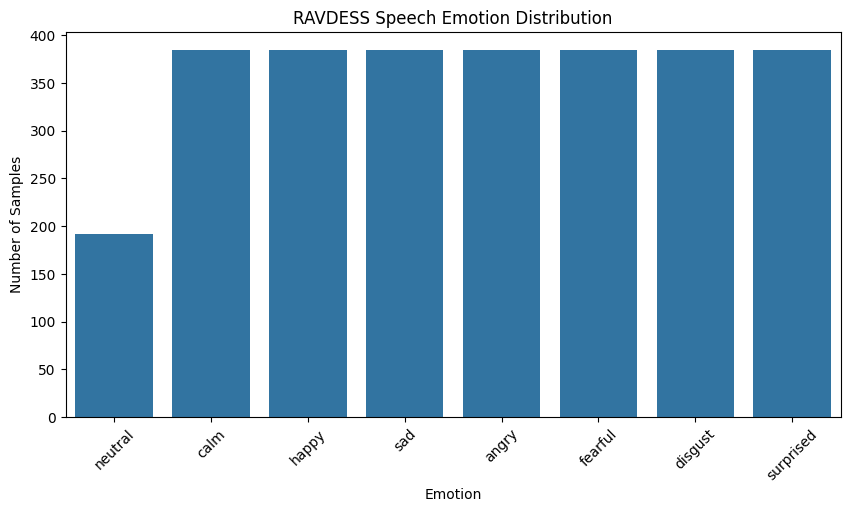

In [21]:
plt.figure(
    figsize=(10, 5)
)

sns.countplot(
    data=df,
    x="emotion",
    order=LABELS
)

plt.title(
    "RAVDESS Speech Emotion Distribution"
)

plt.xlabel(
    "Emotion"
)

plt.ylabel(
    "Number of Samples"
)

plt.xticks(
    rotation=45
)

plt.show()

In [22]:
sample_path = df.iloc[0]["path"]

y, sr = librosa.load(
    sample_path,
    sr=22050
)

print(
    "Emotion:",
    df.iloc[0]["emotion"]
)

print(
    "Sample rate:",
    sr
)

print(
    "Audio duration:",
    len(y) / sr,
    "seconds"
)

Emotion: fearful
Sample rate: 22050
Audio duration: 3.47015873015873 seconds


In [23]:
from IPython.display import Audio, display

display(
    Audio(
        sample_path
    )
)

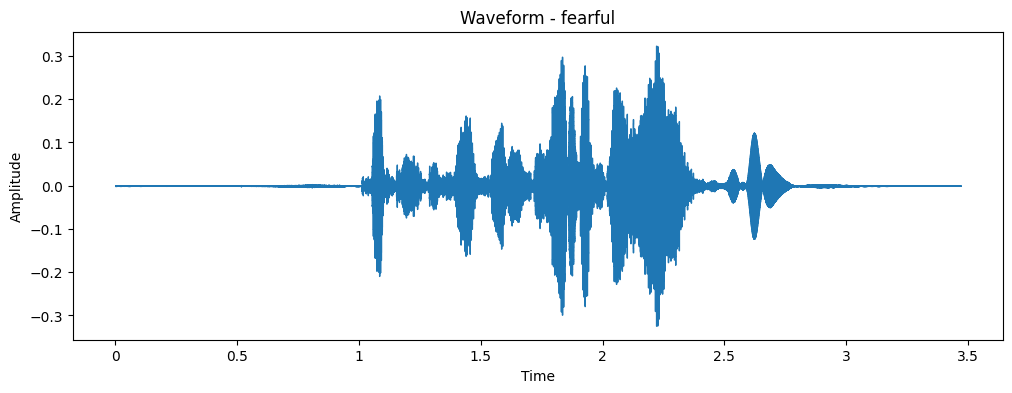

In [24]:
plt.figure(
    figsize=(12, 4)
)

librosa.display.waveshow(
    y,
    sr=sr
)

plt.title(
    f"Waveform - {df.iloc[0]['emotion']}"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "Amplitude"
)

plt.show()

In [25]:
SAMPLE_RATE = 22050

N_MFCC = 40

MAX_LENGTH = 174

print(
    "Sample rate:",
    SAMPLE_RATE
)

print(
    "MFCC:",
    N_MFCC
)

print(
    "Maximum length:",
    MAX_LENGTH
)

Sample rate: 22050
MFCC: 40
Maximum length: 174


In [26]:
def extract_mfcc(
    audio_path,
    sr=SAMPLE_RATE,
    n_mfcc=N_MFCC,
    max_length=MAX_LENGTH
):

    y, sr = librosa.load(
        audio_path,
        sr=sr,
        mono=True
    )

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc
    )

    if mfcc.shape[1] < max_length:

        pad_width = (
            max_length -
            mfcc.shape[1]
        )

        mfcc = np.pad(
            mfcc,
            (
                (0, 0),
                (0, pad_width)
            ),
            mode="constant"
        )

    else:

        mfcc = mfcc[
            :,
            :max_length
        ]

    return mfcc

In [27]:
sample_mfcc = extract_mfcc(
    sample_path
)

print(
    "MFCC shape:",
    sample_mfcc.shape
)

MFCC shape: (40, 174)


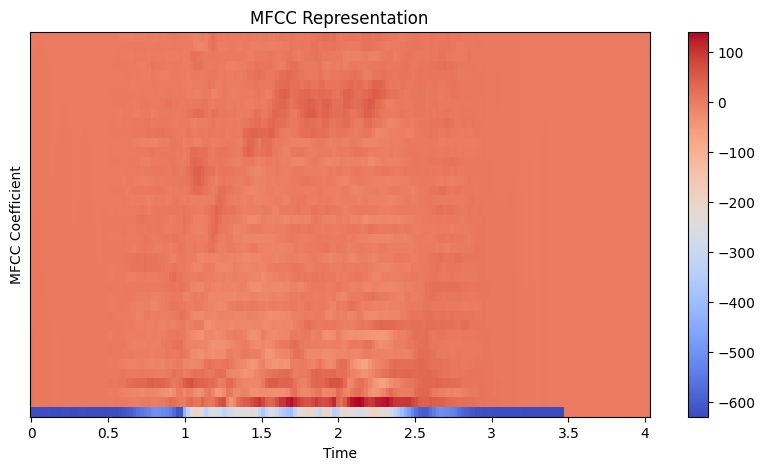

In [28]:
plt.figure(
    figsize=(10, 5)
)

librosa.display.specshow(
    sample_mfcc,
    x_axis="time"
)

plt.colorbar()

plt.title(
    "MFCC Representation"
)

plt.xlabel(
    "Time"
)

plt.ylabel(
    "MFCC Coefficient"
)

plt.show()

In [29]:
actors = sorted(
    df["actor"].unique()
)

print(
    "Actors:",
    actors
)

print(
    "Number of actors:",
    len(actors)
)

Actors: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Number of actors: 24


In [30]:
train_actors = actors[:16]

val_actors = actors[16:20]

test_actors = actors[20:]

print(
    "Train actors:",
    train_actors
)

print(
    "Validation actors:",
    val_actors
)

print(
    "Test actors:",
    test_actors
)

Train actors: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]
Validation actors: [np.int64(17), np.int64(18), np.int64(19), np.int64(20)]
Test actors: [np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


In [31]:
train_df = df[
    df["actor"].isin(
        train_actors
    )
].reset_index(drop=True)

val_df = df[
    df["actor"].isin(
        val_actors
    )
].reset_index(drop=True)

test_df = df[
    df["actor"].isin(
        test_actors
    )
].reset_index(drop=True)

print(
    "Training:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Testing:",
    len(test_df)
)

Training: 1920
Validation: 480
Testing: 480


In [32]:
def create_features(dataframe):

    X = []
    y = []

    total = len(dataframe)

    for i, row in dataframe.iterrows():

        try:

            mfcc = extract_mfcc(
                row["path"]
            )

            X.append(
                mfcc
            )

            y.append(
                LABEL_TO_INDEX[
                    row["emotion"]
                ]
            )

        except Exception as e:

            print(
                "Error:",
                row["path"]
            )

            print(e)

        if (
            (i + 1) % 100 == 0
        ):

            print(
                f"Processed {i+1}/{total}"
            )

    return (
        np.array(
            X,
            dtype=np.float32
        ),
        np.array(y)
    )

In [33]:
X_train, y_train = create_features(
    train_df
)

print(
    "X_train:",
    X_train.shape
)

print(
    "y_train:",
    y_train.shape
)

Processed 100/1920
Processed 200/1920
Processed 300/1920
Processed 400/1920
Processed 500/1920
Processed 600/1920
Processed 700/1920
Processed 800/1920
Processed 900/1920
Processed 1000/1920
Processed 1100/1920
Processed 1200/1920
Processed 1300/1920
Processed 1400/1920
Processed 1500/1920
Processed 1600/1920
Processed 1700/1920
Processed 1800/1920
Processed 1900/1920
X_train: (1920, 40, 174)
y_train: (1920,)


In [34]:
X_test, y_test = create_features(
    test_df
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)

Processed 100/480
Processed 200/480
Processed 300/480
Processed 400/480
X_test: (480, 40, 174)
y_test: (480,)


In [36]:
def create_features(dataframe):

    X = []
    y = []

    total = len(dataframe)

    for i, row in dataframe.iterrows():

        try:
            mfcc = extract_mfcc(row["path"])

            X.append(mfcc)

            y.append(
                LABEL_TO_INDEX[row["emotion"]]
            )

        except Exception as e:

            print("Error:", row["path"])
            print(e)

        if (i + 1) % 100 == 0:
            print(
                f"Processed {i + 1}/{total}"
            )

    X = np.array(X, dtype=np.float32)
    y = np.array(y)

    return X, y

In [37]:
X_train, y_train = create_features(train_df)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

Processed 100/1920
Processed 200/1920
Processed 300/1920
Processed 400/1920
Processed 500/1920
Processed 600/1920
Processed 700/1920
Processed 800/1920
Processed 900/1920
Processed 1000/1920
Processed 1100/1920
Processed 1200/1920
Processed 1300/1920
Processed 1400/1920
Processed 1500/1920
Processed 1600/1920
Processed 1700/1920
Processed 1800/1920
Processed 1900/1920
X_train shape: (1920, 40, 174)
y_train shape: (1920,)


In [38]:
X_val, y_val = create_features(val_df)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

Processed 100/480
Processed 200/480
Processed 300/480
Processed 400/480
X_val shape: (480, 40, 174)
y_val shape: (480,)


In [39]:
X_test, y_test = create_features(test_df)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Processed 100/480
Processed 200/480
Processed 300/480
Processed 400/480
X_test shape: (480, 40, 174)
y_test shape: (480,)


In [40]:
X_train = X_train[..., np.newaxis]

X_val = X_val[..., np.newaxis]

X_test = X_test[..., np.newaxis]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (1920, 40, 174, 1)
X_val: (480, 40, 174, 1)
X_test: (480, 40, 174, 1)


In [41]:
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-8)

X_val = (X_val - mean) / (std + 1e-8)

X_test = (X_test - mean) / (std + 1e-8)

print("Normalization completed.")
print("Training mean:", np.mean(X_train))
print("Training std:", np.std(X_train))

Normalization completed.
Training mean: -1.05755994e-07
Training std: 0.9999996


In [42]:
model = models.Sequential([

    layers.Input(
        shape=X_train.shape[1:]
    ),

    layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Dropout(0.25),

    layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Dropout(0.25),

    layers.Conv2D(
        128, (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D((2, 2)),

    layers.Dropout(0.30),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.40),

    layers.Dense(
        8,
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 174, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 174, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 87, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 87, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 87, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 43, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 43, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 13440)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,720,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,815,048 (6.92 MB)

 Trainable params: 1,814,600 (6.92 MB)

 Non-trainable params: 448 (1.75 KB)

In [44]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (1920, 40, 174, 1)
X_val: (480, 40, 174, 1)
X_test: (480, 40, 174, 1)
y_train: (1920,)
y_val: (480,)
y_test: (480,)


In [45]:
print("Emotion labels:")

for i, label in enumerate(LABELS):
    print(i, "=", label)

Emotion labels:
0 = neutral
1 = calm
2 = happy
3 = sad
4 = angry
5 = fearful
6 = disgust
7 = surprised


In [46]:
model = models.Sequential([

    layers.Input(
        shape=X_train.shape[1:]
    ),

    layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Dropout(0.25),

    layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Dropout(0.25),

    layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Dropout(0.30),

    layers.Flatten(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.40),

    layers.Dense(
        len(LABELS),
        activation="softmax"
    )
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 40, 174, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 40, 174, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 20, 87, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 20, 87, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 20, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 20, 87, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 10, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 10, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 10, 43, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 10, 43, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 5, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 5, 21, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 13440)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,720,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,815,048 (6.92 MB)

 Trainable params: 1,814,600 (6.92 MB)

 Non-trainable params: 448 (1.75 KB)

In [47]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [48]:
early_stopping = callbacks.EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True,

    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1
)

checkpoint = callbacks.ModelCheckpoint(

    "best_speech_emotion_model.keras",

    monitor="val_accuracy",

    save_best_only=True,

    verbose=1
)

print("Callbacks created.")

Callbacks created.


In [49]:
history = model.fit(

    X_train,

    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=40,

    batch_size=32,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 960ms/step - accuracy: 0.1521 - loss: 4.7371
Epoch 1: val_accuracy improved from None to 0.20000, saving model to best_speech_emotion_model.keras

Epoch 1: finished saving model to best_speech_emotion_model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.1500 - loss: 2.9969 - val_accuracy: 0.2000 - val_loss: 2.0342 - learning_rate: 0.0010
Epoch 2/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1642 - loss: 2.0175
Epoch 2: val_accuracy improved from 0.20000 to 0.20417, saving model to best_speech_emotion_model.keras

Epoch 2: finished saving model to best_speech_emotion_model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 105s 1s/step - accuracy: 0.1745 - loss: 2.0195 - val_accuracy: 0.2042 - val_loss: 2.0434 - learning_rate: 0.0010
Epoch 3/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1771 - loss: 2.0065
Epoch 3: val_accuracy did not improve from 0.20417
60/60 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.1677 - loss: 2.0090 - val_

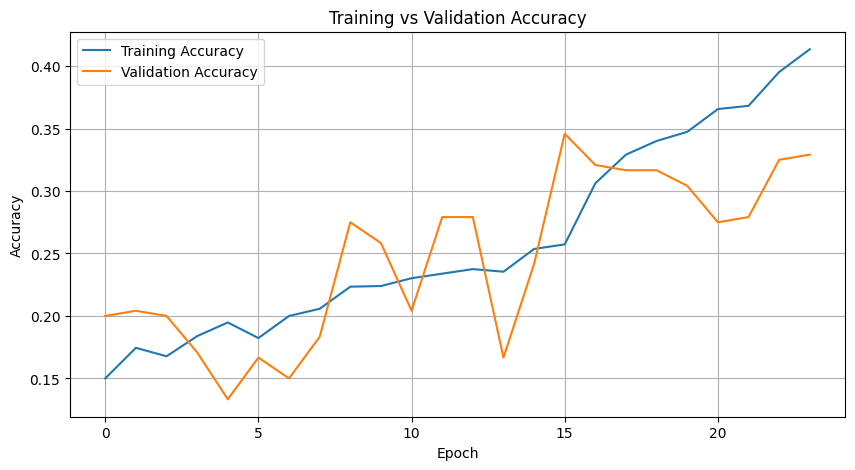

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

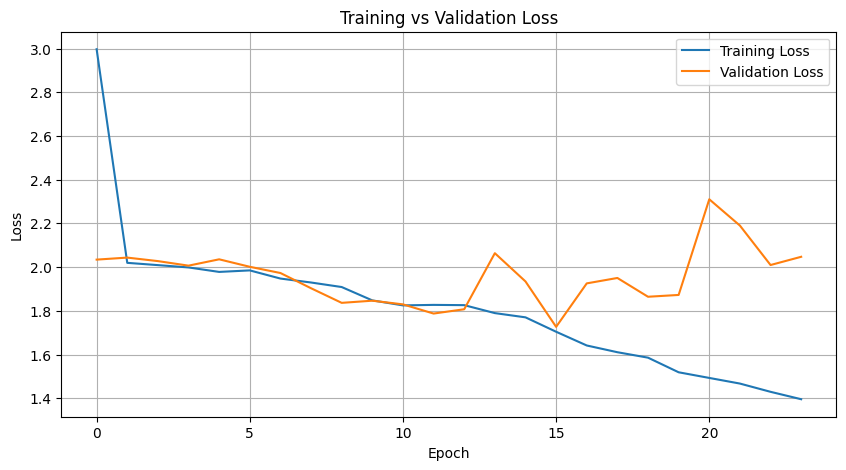

In [51]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Training vs Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [52]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(
    f"Test Accuracy: {test_accuracy * 100:.2f}%"
)

print(
    f"Test Loss: {test_loss:.4f}"
)

15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 235ms/step - accuracy: 0.2792 - loss: 1.7866
Test Accuracy: 27.92%
Test Loss: 1.7866


In [53]:
y_probability = model.predict(
    X_test
)

y_pred = np.argmax(
    y_probability,
    axis=1
)

print("Predictions generated.")

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step
Predictions generated.


In [54]:
print(
    classification_report(

        y_test,

        y_pred,

        labels=range(len(LABELS)),

        target_names=LABELS,

        zero_division=0

    )
)

              precision    recall  f1-score   support

     neutral       0.00      0.00      0.00        32
        calm       0.64      0.56      0.60        64
       happy       0.00      0.00      0.00        64
         sad       0.25      0.25      0.25        64
       angry       0.32      0.31      0.32        64
     fearful       0.18      0.44      0.26        64
     disgust       0.41      0.47      0.43        64
   surprised       0.07      0.06      0.06        64

    accuracy                           0.28       480
   macro avg       0.23      0.26      0.24       480
weighted avg       0.25      0.28      0.26       480



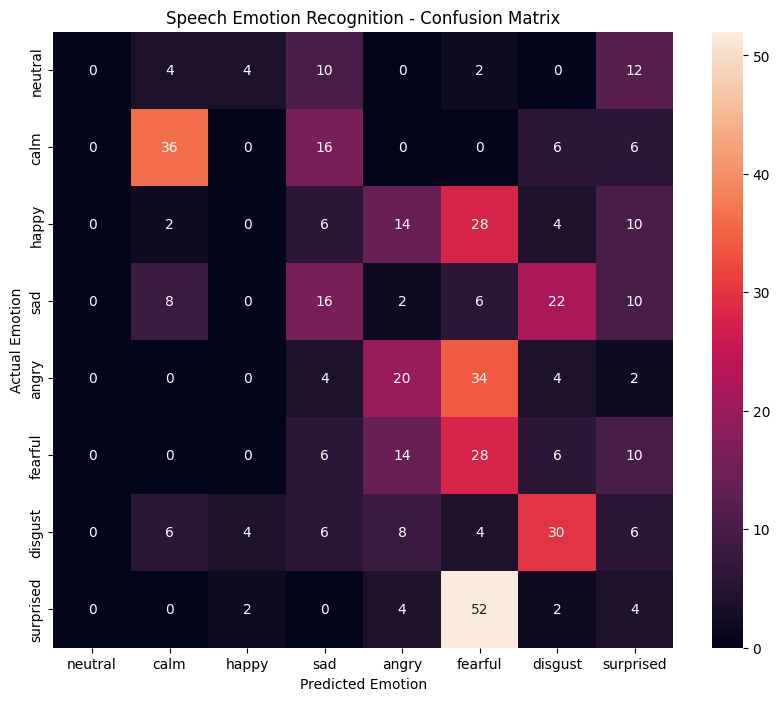

In [55]:
cm = confusion_matrix(

    y_test,

    y_pred,

    labels=range(len(LABELS))

)

plt.figure(
    figsize=(10, 8)
)

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    xticklabels=LABELS,

    yticklabels=LABELS

)

plt.title(
    "Speech Emotion Recognition - Confusion Matrix"
)

plt.xlabel(
    "Predicted Emotion"
)

plt.ylabel(
    "Actual Emotion"
)

plt.show()

In [56]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)

Accuracy  : 27.92%
Precision : 24.92%
Recall    : 27.92%
F1 Score  : 25.65%


In [57]:
model.save(
    "speech_emotion_cnn.keras"
)

print(
    "Model saved successfully."
)

Model saved successfully.


In [58]:
np.save(
    "mfcc_mean.npy",
    mean
)

np.save(
    "mfcc_std.npy",
    std
)

print(
    "Normalization values saved."
)

Normalization values saved.


In [65]:
from google.colab import files

uploaded = files.upload()

new_audio = list(
    uploaded.keys()
)[0]

print(
    "Uploaded file:",
    new_audio
)

Saving universfield-angry-male-voice-you-stupid-cat-352692.mp3 to universfield-angry-male-voice-you-stupid-cat-352692.mp3
Uploaded file: universfield-angry-male-voice-you-stupid-cat-352692.mp3


In [66]:
new_mfcc = extract_mfcc(
    new_audio
)

print(
    "MFCC shape:",
    new_mfcc.shape
)

MFCC shape: (40, 174)


In [67]:
new_mfcc = (
    new_mfcc - mean
) / (
    std + 1e-8
)

new_mfcc = new_mfcc[
    ..., np.newaxis
]

new_mfcc = np.expand_dims(
    new_mfcc,
    axis=0
)

print(
    "Input shape:",
    new_mfcc.shape
)

Input shape: (1, 40, 174, 1)


In [68]:
prediction = model.predict(
    new_mfcc
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_emotion = LABELS[
    predicted_index
]

confidence = prediction[0][
    predicted_index
]

print("================================")
print(
    "Predicted Emotion:",
    predicted_emotion.upper()
)

print(
    f"Confidence: {confidence * 100:.2f}%"
)
print("================================")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Predicted Emotion: HAPPY
Confidence: 36.14%


In [69]:
results = pd.DataFrame({

    "Emotion": LABELS,

    "Probability": prediction[0]

})

results = results.sort_values(
    "Probability",
    ascending=False
)

results

,Emotion,Probability
2,happy,0.361435
5,fearful,0.310462
7,surprised,0.227549
4,angry,0.076017
3,sad,0.023980
6,disgust,0.000469
0,neutral,0.000077
1,calm,0.000011


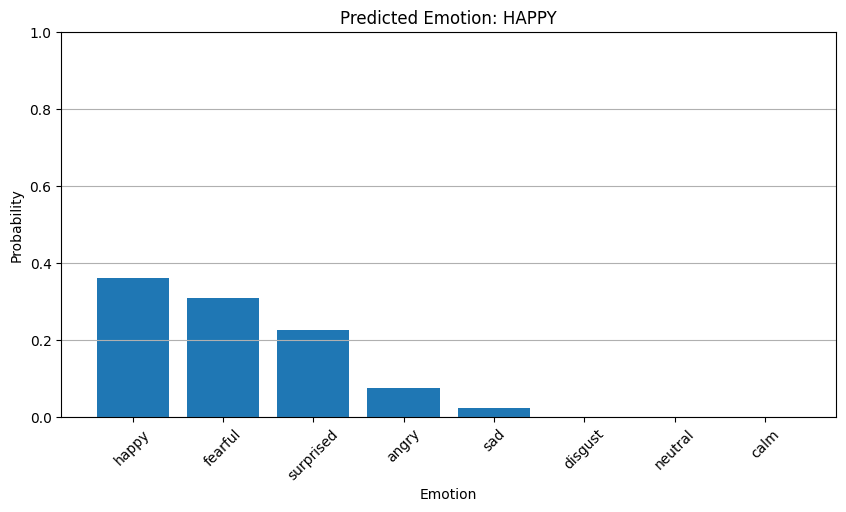

In [70]:
plt.figure(figsize=(10, 5))

plt.bar(
    results["Emotion"],
    results["Probability"]
)

plt.title(
    f"Predicted Emotion: "
    f"{predicted_emotion.upper()}"
)

plt.xlabel("Emotion")

plt.ylabel("Probability")

plt.xticks(
    rotation=45
)

plt.ylim(
    0,
    1
)

plt.grid(
    axis="y"
)

plt.show()